# Image Object Recognition Lab (Google Colab)
**Case Study (Fruits):** Shape/Color Histogram/Raw-image pipelines for multi-class recognition  
**Methods:**  
- Shape-based Chain Code ➜ **ANN**  
- Color Histogram ➜ **ANN**   
- Raw Image ➜ **CNN**

## 0) Setup
We will install a few packages for image processing.

In [2]:

# If you are working inside Google Colab, this command installs the required
# Python packages. The exclamation mark (!) tells Jupyter/Colab to run the line
# as a shell command instead of normal Python code.
#
# -q means "quiet", so the installation prints less output.
#
# Package purpose:
# opencv-python  -> image reading and image processing
# scikit-image   -> extra image processing utilities
# tensorflow     -> deep learning framework used for the CNN
# matplotlib     -> plotting graphs and images
# pandas         -> table-like data handling
# numpy          -> numerical arrays and vector/matrix computations
!pip install -q opencv-python scikit-image tensorflow matplotlib pandas numpy

In [1]:

# Import the Google Drive helper from Google Colab.
# This works only in the Colab environment.
from google.colab import drive

# Mount your Google Drive inside the Colab file system.
# After running this, you will get an authentication link.
# Your files become accessible under /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1) Get the Dataset
Upload and unzip **`fruit_image_dataset.zip`** (provided) which contains subfolders per class and a `labels.csv`.

In [3]:

# os      -> used for path handling, file checks, and directory operations
# zipfile -> used to unzip the dataset archive
# pandas  -> used to read labels.csv into a DataFrame
import os, zipfile, pandas as pd

# glob helps find files matching wildcard patterns such as *.png
from glob import glob

# -----------------------------------------------------------------------------
# OPTION A: Upload the ZIP file directly to Colab
# -----------------------------------------------------------------------------
# These lines are kept commented because in the current notebook we are using
# the ZIP file from Google Drive. If you want to upload manually, uncomment.
#
# from google.colab import files
# uploaded = files.upload()  # A dialog box will let you choose fruit_image_dataset.zip
# with zipfile.ZipFile('fruit_image_dataset.zip','r') as z:
#     z.extractall('fruit_data')  # Extract all files inside folder fruit_data

# -----------------------------------------------------------------------------
# OPTION B: Load the ZIP file from Google Drive
# -----------------------------------------------------------------------------
# This is the path of the ZIP file inside Google Drive.
zip_path = '/content/drive/MyDrive/JISNIT/FDP25/Lab/fruit_image_dataset.zip'

# Check whether the ZIP file actually exists before trying to open it.
if os.path.exists(zip_path):

    # Open the ZIP file in read mode ('r').
    # The variable z will represent the opened zip archive inside this block.
    with zipfile.ZipFile(zip_path, 'r') as z:

        # Extract all contents of the ZIP archive into a new local folder named
        # fruit_data. After extraction, images and labels.csv should appear there.
        z.extractall('fruit_data')

# Read the CSV file that stores image file paths and class labels.
# The result is a pandas DataFrame, which is like a spreadsheet in Python.
labels = pd.read_csv('fruit_data/labels.csv')

# Display the first 5 rows so we can verify the structure of the CSV file.
print(labels.head())

# Show all unique class names present in the dataset.
print("Classes:", labels['label'].unique().tolist())

               filepath  label
0  apple/apple_0000.png  apple
1  apple/apple_0001.png  apple
2  apple/apple_0002.png  apple
3  apple/apple_0003.png  apple
4  apple/apple_0004.png  apple
Classes: ['apple', 'banana', 'orange', 'pear']


### Quick Preview

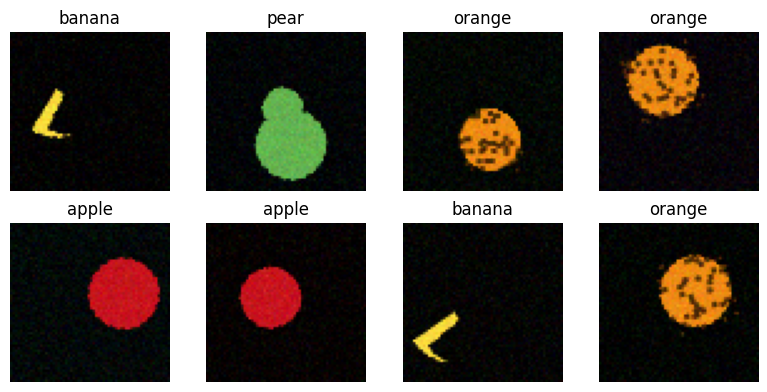

In [4]:

# matplotlib.pyplot -> plotting library used to display images in a grid
import matplotlib.pyplot as plt

# numpy is imported here because it is commonly used in image notebooks
import numpy as np

# PIL.Image is another image reader (different from OpenCV)
from PIL import Image

# Randomly pick 8 rows from the labels table for visual inspection.
# random_state=0 ensures the same 8 examples are selected every time.
samples = labels.sample(8, random_state=0)

# Create a figure canvas of width 8 inches and height 4 inches.
plt.figure(figsize=(8, 4))

# Loop over the sampled rows one by one.
# enumerate(..., 1) starts numbering from 1 because subplot indexing starts at 1.
for i, (_, row) in enumerate(samples.iterrows(), 1):

    # Build the full path to the image by joining the base folder ('fruit_data')
    # with the relative file path stored in the CSV.
    #
    # Image.open(...) loads the image using PIL.
    # .convert('RGB') forces the image into 3-channel RGB format.
    img = Image.open(os.path.join('fruit_data', row['filepath'])).convert('RGB')

    # Create the i-th subplot in a 2-row by 4-column grid.
    ax = plt.subplot(2, 4, i)

    # Show the image in that subplot.
    ax.imshow(img)

    # Put the class label as the title of the subplot.
    ax.set_title(row['label'])

    # Hide axis ticks and borders for a cleaner display.
    ax.axis('off')

# Adjust spacing so titles and images do not overlap.
plt.tight_layout()

# Render the full figure.
plt.show()

## 2) Train/Val/Test Split
We'll create splits and a **tf.data** loader for CNN-based parts.

In [5]:

# os      -> directory and path operations
# shutil  -> copying files into train/val/test folders
# pandas  -> table handling
# numpy   -> numerical utilities
import os, shutil, pandas as pd, numpy as np

# train_test_split helps create train/validation/test partitions
from sklearn.model_selection import train_test_split

# Create a copy of the labels DataFrame so the original object remains unchanged.
df = labels.copy()

# -------------------------------------------------------------------------
# First split: separate out the test set
# -------------------------------------------------------------------------
# test_size=0.2 means 20% of the total data will go to the test set.
# stratify=df['label'] preserves class proportions across the split.
# random_state=42 makes the split reproducible.
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['label'],
    random_state=42
)

# -------------------------------------------------------------------------
# Second split: separate out the validation set from the remaining training set
# -------------------------------------------------------------------------
# Again we stratify so every class remains proportionally represented.
train_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    stratify=train_df['label'],
    random_state=42
)

# -------------------------------------------------------------------------
# Create directory structure and physically copy images into train/val/test
# -------------------------------------------------------------------------
# This loop runs once for each split:
#   name -> 'train', 'val', or 'test'
#   part -> the corresponding DataFrame of rows
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:

    # Create the main split folder, e.g. fruit_split/train
    os.makedirs(f"fruit_split/{name}", exist_ok=True)

    # Create one subfolder per class inside the split folder.
    # Example: fruit_split/train/apple, fruit_split/train/banana, ...
    for cls in part['label'].unique():
        os.makedirs(f"fruit_split/{name}/{cls}", exist_ok=True)

    # Loop through every image entry in the split DataFrame.
    for _, r in part.iterrows():

        # Source path of the original image in fruit_data
        src = os.path.join('fruit_data', r['filepath'])

        # Destination path inside the class-specific split folder.
        # os.path.basename(...) keeps only the filename, not the entire path.
        dst = os.path.join(
            "fruit_split",
            name,
            r['label'],
            os.path.basename(r['filepath'])
        )

        # Copy only if the file is not already present.
        if not os.path.exists(dst):
            shutil.copy(src, dst)

# Print the number of samples in train, validation, and test splits.
len(train_df), len(val_df), len(test_df)

(281, 71, 88)

## 3) Shape-based Features: Chain Code ➜ ANN
**Idea:** Extract the largest contour from a binary mask and compute the **Freeman chain code** along the boundary.  
We build a histogram of 8 directional codes (0–7) normalized; optionally add simple shape stats (area, perimeter ratio).

In [6]:

# cv2     -> OpenCV, used for reading images and contour extraction
# numpy   -> numerical array operations
# os      -> directory handling
# pandas  -> table creation
import cv2, numpy as np, os, pandas as pd

# glob helps retrieve all PNG files under a folder pattern.
from glob import glob

# -----------------------------------------------------------------------------
# Function: chain_code_hist
# Purpose : Convert one image into a 10-dimensional shape feature vector
# -----------------------------------------------------------------------------
def chain_code_hist(img_path, thresh=30):

    # Read the image in grayscale mode.
    # This returns a 2D array of pixel intensities instead of a 3D RGB image.
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    # Convert the grayscale image to a binary image.
    # Pixel values >= thresh become 255 (white), below thresh become 0 (black).
    # The first returned value is the threshold used, which we ignore with "_".
    _, bw = cv2.threshold(img, thresh, 255, cv2.THRESH_BINARY)

    # Find contours (object boundaries) in the binary image.
    # cv2.RETR_EXTERNAL tells OpenCV to keep only outermost contours.
    # cv2.CHAIN_APPROX_NONE keeps all contour points without compression.
    cnts, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    # If no contour is found, return a zero vector of length 10.
    # This prevents the code from crashing on bad/empty images.
    if len(cnts) == 0:
        return np.zeros(10)

    # Choose the largest contour by area.
    # The assumption is that the main fruit object is the largest component.
    cnt = max(cnts, key=cv2.contourArea)

    # Define the 8 possible Freeman chain code directions.
    # These directions represent local movement along the contour boundary.
    dirs = [
        (1, 0),   # 0: right
        (1, 1),   # 1: down-right / diagonal
        (0, 1),   # 2: down
        (-1, 1),  # 3: down-left
        (-1, 0),  # 4: left
        (-1, -1), # 5: up-left
        (0, -1),  # 6: up
        (1, -1)   # 7: up-right
    ]

    # Create an 8-bin histogram to count how frequently each chain direction occurs.
    hist = np.zeros(8, dtype=np.float32)

    # perim will count the number of valid contour steps, which acts like
    # a simple perimeter estimate.
    perim = 0.0

    # Walk through contour points one pair at a time.
    for i in range(1, len(cnt)):

        # Extract previous point (x0, y0) and current point (x1, y1)
        x0, y0 = cnt[i - 1][0]
        x1, y1 = cnt[i][0]

        # Compute movement between the two contour points.
        # np.clip(..., -1, 1) forces values into the chain-code neighborhood range.
        dx = np.clip(x1 - x0, -1, 1)
        dy = np.clip(y1 - y0, -1, 1)

        # Represent the movement as a 2D step tuple.
        step = (dx, dy)

        # If the step is (0, 0), there is no movement; skip it.
        if step == (0, 0):
            continue

        # Try to map the step exactly to one of the 8 chain-code directions.
        try:
            idx = dirs.index((int(np.sign(dx)), int(np.sign(dy))))

        # If exact matching somehow fails, choose the nearest valid direction.
        except ValueError:
            diffs = [abs(dx - d[0]) + abs(dy - d[1]) for d in dirs]
            idx = int(np.argmin(diffs))

        # Increase the count of the corresponding direction.
        hist[idx] += 1

        # Increase the perimeter-like step count.
        perim += 1

    # Normalize the histogram so its values sum approximately to 1.
    # 1e-6 avoids division by zero.
    hist = hist / (hist.sum() + 1e-6)

    # Compute contour area.
    area = cv2.contourArea(cnt)

    # Compute the bounding rectangle around the contour.
    x, y, w, h = cv2.boundingRect(cnt)

    # Aspect ratio = width / height
    aspect = w / (h + 1e-6)

    # Extent = area / area of bounding box
    # This is computed here as an informative shape statistic,
    # though it is not included in the final returned vector.
    extent = area / (w * h + 1e-6)

    # Return a 10-dimensional feature vector:
    # 8 normalized chain-code bins
    # + perimeter/area ratio
    # + aspect ratio
    return np.hstack([hist, [perim / (area + 1e-6), aspect]]).astype(np.float32)

# -----------------------------------------------------------------------------
# Function: build_chaincode_features
# Purpose : Apply chain_code_hist to all images in one split directory
# -----------------------------------------------------------------------------
def build_chaincode_features(split_dir):

    # rows will store one dictionary per image.
    rows = []

    # Go through class folders in sorted order for consistency.
    for cls in sorted(os.listdir(split_dir)):

        # Find all PNG images inside the class folder.
        for f in sorted(glob(os.path.join(split_dir, cls, "*.png"))):

            # Extract the 10-dimensional chain-code feature vector.
            feat = chain_code_hist(f)

            # Build a row dictionary containing:
            # - image path
            # - class label
            # - features named cc0, cc1, ..., cc9
            rows.append({
                "path": f,
                "label": cls,
                **{f"cc{i}": feat[i] for i in range(len(feat))}
            })

    # Convert the list of row dictionaries to a pandas DataFrame.
    return pd.DataFrame(rows)

# Build chain-code feature tables for training, validation, and test splits.
train_cc = build_chaincode_features("fruit_split/train")
val_cc   = build_chaincode_features("fruit_split/val")
test_cc  = build_chaincode_features("fruit_split/test")

# Show the first few rows to inspect the resulting feature table.
train_cc.head()

,path,label,cc0,cc1,cc2,cc3,cc4,cc5,cc6,cc7,cc8,cc9
0,fruit_split/train/apple/apple_0000.png,apple,0.146667,0.093333,0.173333,0.093333,0.146667,0.106667,0.120000,0.120000,0.147638,1.000000
1,fruit_split/train/apple/apple_0005.png,apple,0.134328,0.104478,0.149254,0.119403,0.134328,0.089552,0.149254,0.119403,0.154378,1.000000
2,fruit_split/train/apple/apple_0006.png,apple,0.153846,0.102564,0.153846,0.102564,0.141026,0.102564,0.141026,0.102564,0.131203,1.000000
3,fruit_split/train/apple/apple_0008.png,apple,0.162500,0.100000,0.137500,0.112500,0.150000,0.087500,0.150000,0.100000,0.134567,1.000000
4,fruit_split/train/apple/apple_0009.png,apple,0.164706,0.105882,0.129412,0.105882,0.152941,0.094118,0.152941,0.094118,0.124633,1.033333


In [7]:

# StandardScaler -> standardizes numerical features (zero mean, unit variance)
# LabelEncoder   -> converts string labels like 'apple' into integers
from sklearn.preprocessing import StandardScaler, LabelEncoder

# MLPClassifier is a feed-forward neural network (ANN) from scikit-learn
from sklearn.neural_network import MLPClassifier

# Evaluation tools for classification performance
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# numpy imported for possible array operations
import numpy as np

# -----------------------------------------------------------------------------
# Encode class labels into integers
# -----------------------------------------------------------------------------
le = LabelEncoder()

# fit_transform learns the mapping from text labels to integers on the training set
# Example: apple -> 0, banana -> 1, orange -> 2
y_tr = le.fit_transform(train_cc["label"])

# transform applies the already-learned mapping to validation and test labels
y_va = le.transform(val_cc["label"])
y_te = le.transform(test_cc["label"])

# -----------------------------------------------------------------------------
# Extract only the chain-code feature columns
# -----------------------------------------------------------------------------
# .filter(like="cc") selects columns whose names contain "cc"
X_tr = train_cc.filter(like="cc").values
X_va = val_cc.filter(like="cc").values
X_te = test_cc.filter(like="cc").values

# -----------------------------------------------------------------------------
# Standardize the features
# -----------------------------------------------------------------------------
# This is important because neural networks usually train better when features
# are on comparable scales.
sc = StandardScaler()

# Learn scaling parameters from training data and transform it
X_trs = sc.fit_transform(X_tr)

# Use the same scaling parameters on validation and test data
X_vas = sc.transform(X_va)
X_tes = sc.transform(X_te)

# -----------------------------------------------------------------------------
# Define the ANN model
# -----------------------------------------------------------------------------
mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),  # two hidden layers with 128 and 64 neurons
    activation='relu',             # ReLU activation function
    max_iter=400,                  # maximum number of training iterations
    random_state=0                 # fixed seed for reproducibility
)

# Train the ANN using the scaled training features and encoded labels.
mlp.fit(X_trs, y_tr)

# Predict class indices on the test set.
pred = mlp.predict(X_tes)

# Print overall classification accuracy.
print("Chain Code ➜ ANN accuracy:", accuracy_score(y_te, pred))

# Print precision, recall, F1-score, and support for each class.
print(classification_report(y_te, pred, target_names=le.classes_))

# Print the confusion matrix.
print(confusion_matrix(y_te, pred))

Chain Code ➜ ANN accuracy: 0.8295454545454546
              precision    recall  f1-score   support

       apple       0.74      0.64      0.68        22
      banana       1.00      0.95      0.98        22
      orange       0.65      0.77      0.71        22
        pear       0.95      0.95      0.95        22

    accuracy                           0.83        88
   macro avg       0.84      0.83      0.83        88
weighted avg       0.84      0.83      0.83        88

[[14  0  8  0]
 [ 0 21  0  1]
 [ 5  0 17  0]
 [ 0  0  1 21]]


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (400) reached and the optimization hasn't converged yet.
  warnings.warn(


### Detailed evaluation for Chain Code ➜ ANN

The following cell computes the **confusion matrix heatmap**, prints
**Accuracy / Recall / Precision / F1-score**, and plots the **training loss
profile** of the ANN used with chain-code features.


=== Chain Code -> ANN : Summary Metrics ===
Accuracy           : 0.8295
Precision (macro)  : 0.8363
Recall (macro)     : 0.8295
F1-score (macro)   : 0.8306
Precision (weighted): 0.8363
Recall (weighted)   : 0.8295
F1-score (weighted) : 0.8306


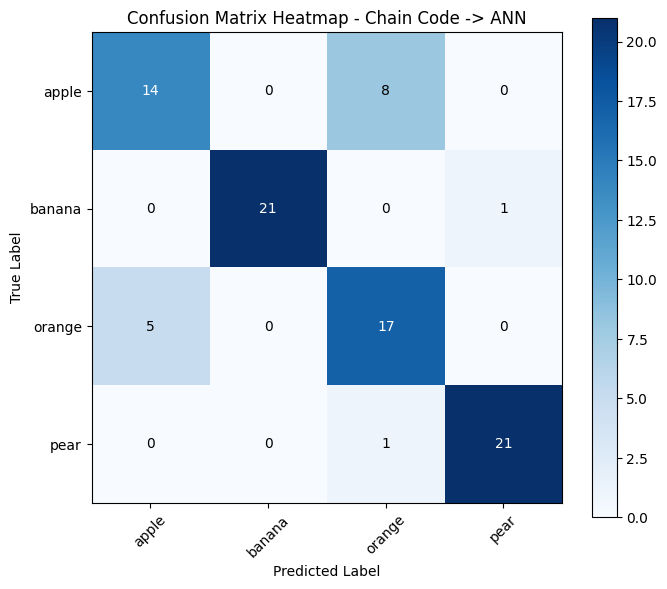

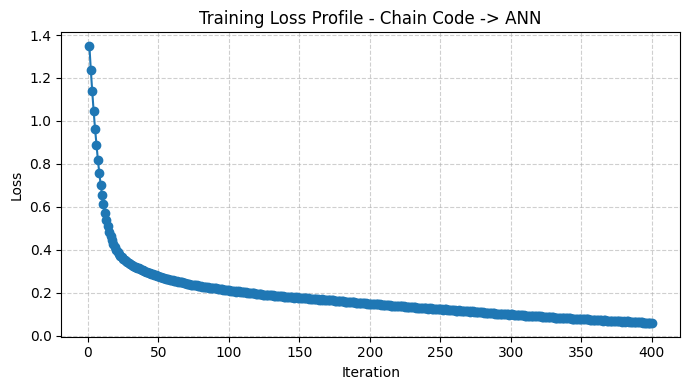

In [8]:
# Detailed evaluation for the Chain Code -> ANN classifier

# Import evaluation metrics:
# confusion_matrix               -> gives counts of true vs predicted classes
# accuracy_score                 -> overall percentage of correct predictions
# precision_recall_fscore_support-> precision, recall, and F1-score values
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support

# Store the true labels and predictions in dedicated variables so that they are
# not overwritten later by the histogram-based classifier.
y_te_cc = y_te
pred_cc = pred

# Compute the confusion matrix for the chain-code classifier.
cm_cc = confusion_matrix(y_te_cc, pred_cc)

# Compute summary metrics.
chain_acc = accuracy_score(y_te_cc, pred_cc)
chain_precision_macro, chain_recall_macro, chain_f1_macro, _ = precision_recall_fscore_support(
    y_te_cc, pred_cc, average="macro", zero_division=0
)
chain_precision_weighted, chain_recall_weighted, chain_f1_weighted, _ = precision_recall_fscore_support(
    y_te_cc, pred_cc, average="weighted", zero_division=0
)

# Print the metrics clearly.
print("=== Chain Code -> ANN : Summary Metrics ===")
print(f"Accuracy           : {chain_acc:.4f}")
print(f"Precision (macro)  : {chain_precision_macro:.4f}")
print(f"Recall (macro)     : {chain_recall_macro:.4f}")
print(f"F1-score (macro)   : {chain_f1_macro:.4f}")
print(f"Precision (weighted): {chain_precision_weighted:.4f}")
print(f"Recall (weighted)   : {chain_recall_weighted:.4f}")
print(f"F1-score (weighted) : {chain_f1_weighted:.4f}")

# Plot the confusion matrix as a heatmap using only matplotlib.
plt.figure(figsize=(7, 6))
plt.imshow(cm_cc, interpolation='nearest', cmap='Blues')
plt.title("Confusion Matrix Heatmap - Chain Code -> ANN")
plt.colorbar()

# Put class names on the x-axis and y-axis.
tick_marks = np.arange(len(le.classes_))
plt.xticks(tick_marks, le.classes_, rotation=45)
plt.yticks(tick_marks, le.classes_)

# Write the numerical value inside each cell of the heatmap.
thresh = cm_cc.max() / 2.0 if cm_cc.size > 0 else 0.0
for r in range(cm_cc.shape[0]):
    for c in range(cm_cc.shape[1]):
        plt.text(
            c, r, str(cm_cc[r, c]),
            ha="center",
            va="center",
            color="white" if cm_cc[r, c] > thresh else "black"
        )

plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()

# Plot the ANN training loss profile.
# MLPClassifier stores the loss value from each training iteration in loss_curve_.
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, marker='o')
plt.title("Training Loss Profile - Chain Code -> ANN")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 4) Color Histogram ➜ ANN
Compute a simple 3×8-bin RGB histogram (24D feature) and train an MLP.

In [9]:

# Import required libraries for color feature extraction
import cv2, numpy as np, os, pandas as pd
from glob import glob

# -----------------------------------------------------------------------------
# Function: rgb_hist24
# Purpose : Convert one RGB image into a 24-dimensional color histogram vector
# -----------------------------------------------------------------------------
def rgb_hist24(img_path, bins=8):

    # OpenCV reads color images in BGR order by default.
    # [:, :, ::-1] reverses the channel order and converts BGR -> RGB.
    img = cv2.imread(img_path)[:, :, ::-1]

    # This list will store the histogram of each color channel.
    hists = []

    # Loop over the 3 channels: R, G, B
    for c in range(3):

        # Compute an intensity histogram for one channel.
        # bins=8      -> divide the channel range into 8 intervals
        # range=(0,255) -> pixel values are assumed to lie in this range
        # density=True  -> normalize the histogram to represent relative density
        hist, _ = np.histogram(
            img[:, :, c],
            bins=bins,
            range=(0, 255),
            density=True
        )

        # Convert to float32 and store it.
        hists.append(hist.astype(np.float32))

    # Combine the three 8-bin histograms into one 24-dimensional vector.
    return np.hstack(hists).astype(np.float32)

# -----------------------------------------------------------------------------
# Function: build_hist_features
# Purpose : Apply rgb_hist24 to every image in a split
# -----------------------------------------------------------------------------
def build_hist_features(split_dir):

    # rows will accumulate one dictionary per image.
    rows = []

    # Visit each class folder.
    for cls in sorted(os.listdir(split_dir)):

        # Find all PNG images inside that class folder.
        for f in sorted(glob(os.path.join(split_dir, cls, "*.png"))):

            # Extract the 24-dimensional histogram feature vector.
            feat = rgb_hist24(f, bins=8)

            # Store path, label, and histogram features h0 ... h23
            rows.append({
                "path": f,
                "label": cls,
                **{f"h{i}": feat[i] for i in range(len(feat))}
            })

    # Convert the collected rows into a DataFrame.
    return pd.DataFrame(rows)

# Build histogram feature tables for all three splits.
train_h = build_hist_features("fruit_split/train")
val_h   = build_hist_features("fruit_split/val")
test_h  = build_hist_features("fruit_split/test")

# Preview the first few rows.
train_h.head()

,path,label,h0,h1,h2,h3,h4,h5,h6,h7,...,h14,h15,h16,h17,h18,h19,h20,h21,h22,h23
0,fruit_split/train/apple/apple_0000.png,apple,0.027053,0.000046,0.000107,0.000069,0.000023,0.000643,0.003424,0.000008,...,0.0,0.0,0.029665,0.001708,0.0,0.0,0.0,0.0,0.0,0.0
1,fruit_split/train/apple/apple_0005.png,apple,0.027627,0.000100,0.000084,0.000061,0.000054,0.000559,0.002888,0.000000,...,0.0,0.0,0.029864,0.001509,0.0,0.0,0.0,0.0,0.0,0.0
2,fruit_split/train/apple/apple_0006.png,apple,0.026394,0.000084,0.000069,0.000054,0.000054,0.000973,0.003745,0.000000,...,0.0,0.0,0.029542,0.001831,0.0,0.0,0.0,0.0,0.0,0.0
3,fruit_split/train/apple/apple_0008.png,apple,0.026348,0.000130,0.000077,0.000046,0.000077,0.000843,0.003853,0.000000,...,0.0,0.0,0.029419,0.001953,0.0,0.0,0.0,0.0,0.0,0.0
4,fruit_split/train/apple/apple_0009.png,apple,0.025666,0.000130,0.000084,0.000061,0.000069,0.000957,0.004396,0.000008,...,0.0,0.0,0.029228,0.002145,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:

# Import preprocessing, model, and evaluation tools
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# -----------------------------------------------------------------------------
# Encode labels into integer form
# -----------------------------------------------------------------------------
# Fit the label encoder on training labels only.
le2 = LabelEncoder().fit(train_h["label"])

# Transform labels of train, validation, and test sets.
# Note: this notebook uses semicolons to place multiple statements on one line.
y_tr = le2.transform(train_h["label"])
y_va = le2.transform(val_h["label"])
y_te = le2.transform(test_h["label"])

# -----------------------------------------------------------------------------
# Select only the numerical histogram feature columns
# -----------------------------------------------------------------------------
# The DataFrame also contains 'path' and 'label' columns, which should NOT be
# fed into the model. So we explicitly keep only columns starting with 'h'.
feature_cols = [col for col in train_h.columns if col.startswith('h')]

# Convert the selected feature columns into NumPy arrays.
X_tr = train_h[feature_cols].values
X_va = val_h[feature_cols].values
X_te = test_h[feature_cols].values

# -----------------------------------------------------------------------------
# Standardize the histogram features
# -----------------------------------------------------------------------------
# Fit the scaler on the training set only.
sc2 = StandardScaler().fit(X_tr)

# Apply the same scaling to train, validation, and test features.
X_trs = sc2.transform(X_tr)
X_vas = sc2.transform(X_va)
X_tes = sc2.transform(X_te)

# -----------------------------------------------------------------------------
# Define and train the ANN classifier
# -----------------------------------------------------------------------------
mlp2 = MLPClassifier(
    hidden_layer_sizes=(128, 64),  # same two-hidden-layer architecture
    activation='relu',             # ReLU activation
    max_iter=400,                  # up to 400 training iterations
    random_state=1                 # reproducibility seed
)

# Fit the model on the scaled training histogram features.
mlp2.fit(X_trs, y_tr)

# Predict class labels for the test set.
pred2 = mlp2.predict(X_tes)

# Print overall accuracy.
print("Histogram ➜ ANN accuracy:", accuracy_score(y_te, pred2))

# Detailed class-wise evaluation report.
print(classification_report(y_te, pred2, target_names=le2.classes_))

# Confusion matrix of true versus predicted labels.
print(confusion_matrix(y_te, pred2))

Histogram ➜ ANN accuracy: 1.0
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        22
      banana       1.00      1.00      1.00        22
      orange       1.00      1.00      1.00        22
        pear       1.00      1.00      1.00        22

    accuracy                           1.00        88
   macro avg       1.00      1.00      1.00        88
weighted avg       1.00      1.00      1.00        88

[[22  0  0  0]
 [ 0 22  0  0]
 [ 0  0 22  0]
 [ 0  0  0 22]]


### Detailed evaluation for Color Histogram ➜ ANN

This cell computes the **confusion matrix heatmap**, prints
**Accuracy / Recall / Precision / F1-score**, and plots the **training loss
profile** of the ANN trained on RGB histogram features.


=== Color Histogram -> ANN : Summary Metrics ===
Accuracy            : 1.0000
Precision (macro)   : 1.0000
Recall (macro)      : 1.0000
F1-score (macro)    : 1.0000
Precision (weighted): 1.0000
Recall (weighted)   : 1.0000
F1-score (weighted) : 1.0000


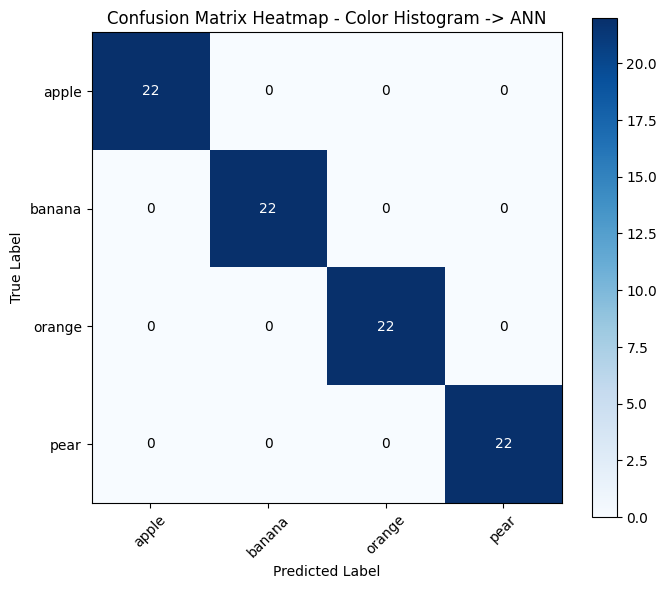

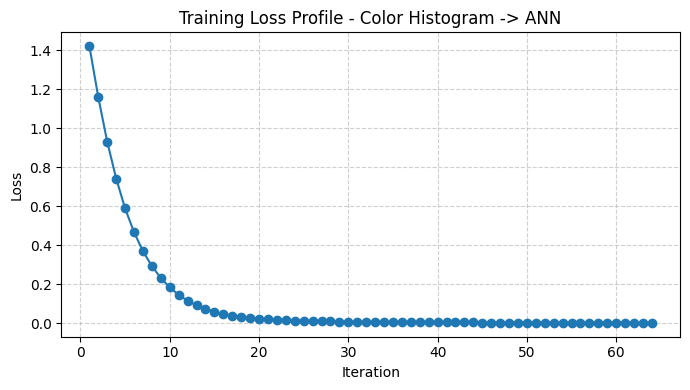

In [11]:
# Detailed evaluation for the Color Histogram -> ANN classifier

from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support

# Save the labels and predictions in dedicated variables before any later cell can
# overwrite them.
y_te_hist = y_te
pred_hist = pred2

# Confusion matrix for histogram-based classifier.
cm_hist = confusion_matrix(y_te_hist, pred_hist)

# Compute summary metrics.
hist_acc = accuracy_score(y_te_hist, pred_hist)
hist_precision_macro, hist_recall_macro, hist_f1_macro, _ = precision_recall_fscore_support(
    y_te_hist, pred_hist, average="macro", zero_division=0
)
hist_precision_weighted, hist_recall_weighted, hist_f1_weighted, _ = precision_recall_fscore_support(
    y_te_hist, pred_hist, average="weighted", zero_division=0
)

# Print the metrics clearly.
print("=== Color Histogram -> ANN : Summary Metrics ===")
print(f"Accuracy            : {hist_acc:.4f}")
print(f"Precision (macro)   : {hist_precision_macro:.4f}")
print(f"Recall (macro)      : {hist_recall_macro:.4f}")
print(f"F1-score (macro)    : {hist_f1_macro:.4f}")
print(f"Precision (weighted): {hist_precision_weighted:.4f}")
print(f"Recall (weighted)   : {hist_recall_weighted:.4f}")
print(f"F1-score (weighted) : {hist_f1_weighted:.4f}")

# Plot confusion matrix heatmap.
plt.figure(figsize=(7, 6))
plt.imshow(cm_hist, interpolation='nearest', cmap='Blues')
plt.title("Confusion Matrix Heatmap - Color Histogram -> ANN")
plt.colorbar()

tick_marks = np.arange(len(le2.classes_))
plt.xticks(tick_marks, le2.classes_, rotation=45)
plt.yticks(tick_marks, le2.classes_)

thresh = cm_hist.max() / 2.0 if cm_hist.size > 0 else 0.0
for r in range(cm_hist.shape[0]):
    for c in range(cm_hist.shape[1]):
        plt.text(
            c, r, str(cm_hist[r, c]),
            ha="center",
            va="center",
            color="white" if cm_hist[r, c] > thresh else "black"
        )

plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()

# Plot the loss profile of the MLP trained on histogram features.
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(mlp2.loss_curve_) + 1), mlp2.loss_curve_, marker='o')
plt.title("Training Loss Profile - Color Histogram -> ANN")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 5) Raw Image ➜ CNN
A small baseline CNN on raw RGB images.

In [12]:

# tensorflow -> deep learning library
# numpy      -> numerical arrays
# cv2        -> image loading
# os         -> folder traversal
import tensorflow as tf, numpy as np, cv2, os

# keras is TensorFlow's high-level neural network API
from tensorflow import keras

# -----------------------------------------------------------------------------
# Function: load_rgb_tensor
# Purpose : Read all PNG images from a split folder into NumPy arrays
# -----------------------------------------------------------------------------
def load_rgb_tensor(folder):

    # X will store image arrays
    # y will store integer labels
    # cls_list stores class names in sorted order
    X, y, cls_list = [], [], sorted(os.listdir(folder))

    # Loop over class folders; idx becomes the numeric label
    for idx, cls in enumerate(cls_list):

        # Loop over all files inside that class folder
        for fn in sorted(os.listdir(os.path.join(folder, cls))):

            # Skip any file that is not a PNG image
            if not fn.endswith(".png"):
                continue

            # Build full file path
            p = os.path.join(folder, cls, fn)

            # Read image using OpenCV, then convert BGR -> RGB
            img = cv2.imread(p)[:, :, ::-1]

            # Append image array to X
            X.append(img)

            # Append the numeric class index to y
            y.append(idx)

    # Convert list of images to a NumPy array and normalize pixel values
    # from [0, 255] to [0, 1].
    X = np.array(X).astype("float32") / 255.0

    # Convert labels to a NumPy integer array
    y = np.array(y).astype("int32")

    # Return image tensor, label vector, and class names
    return X, y, cls_list

# Load the training, validation, and test image tensors.
Xtr, ytr, classes = load_rgb_tensor("fruit_split/train")
Xva, yva, _ = load_rgb_tensor("fruit_split/val")
Xte, yte, _ = load_rgb_tensor("fruit_split/test")

# Number of output classes for the final softmax layer
num_classes = len(classes)

# -----------------------------------------------------------------------------
# Build a simple baseline CNN
# -----------------------------------------------------------------------------
cnn = keras.Sequential([

    # Input image shape: 64x64 pixels with 3 color channels (RGB)
    keras.layers.Input(shape=(64, 64, 3)),

    # First convolution block:
    # 32 filters, kernel size 3x3, ReLU activation, same padding
    keras.layers.Conv2D(32, 3, activation="relu", padding="same"),

    # Downsample feature maps by a factor of 2
    keras.layers.MaxPooling2D(),

    # Second convolution block:
    # 64 filters, again using 3x3 kernels
    keras.layers.Conv2D(64, 3, activation="relu", padding="same"),

    # Another downsampling layer
    keras.layers.MaxPooling2D(),

    # Flatten the 2D feature maps into a 1D vector
    keras.layers.Flatten(),

    # Dense hidden layer with 128 neurons
    keras.layers.Dense(128, activation="relu"),

    # Final classification layer
    # softmax outputs a probability distribution over all classes
    keras.layers.Dense(num_classes, activation="softmax")
])

# -----------------------------------------------------------------------------
# Compile the CNN
# -----------------------------------------------------------------------------
cnn.compile(
    optimizer=keras.optimizers.Adam(1e-3),         # Adam optimizer, learning rate = 0.001
    loss="sparse_categorical_crossentropy",        # suitable for integer-coded multiclass labels
    metrics=["accuracy"]                           # track accuracy during training
)

# EarlyStopping will stop training when validation loss stops improving.
# patience=8 means wait 8 epochs before stopping.
# restore_best_weights=True restores the best model seen during training.
es2 = keras.callbacks.EarlyStopping(
    patience=8,
    restore_best_weights=True,
    monitor="val_loss"
)

# Train the CNN.
# validation_data=(Xva, yva) lets us monitor performance on unseen validation data.
# epochs=40 means at most 40 full passes over the training set.
# batch_size=64 means 64 images are processed per gradient update.
# verbose=0 suppresses per-epoch printed output.
hist2 = cnn.fit(
    Xtr,
    ytr,
    validation_data=(Xva, yva),
    epochs=40,
    batch_size=64,
    callbacks=[es2],
    verbose=0
)

# Evaluate the trained CNN on the final test set.
loss, acc = cnn.evaluate(Xte, yte, verbose=0)

# Print test accuracy.
print("Raw Image ➜ CNN accuracy:", acc)

Raw Image ➜ CNN accuracy: 1.0


### Detailed evaluation for Raw Image ➜ CNN

This cell generates the **confusion matrix heatmap**, prints
**Accuracy / Recall / Precision / F1-score**, and plots the **training and
validation loss curves** of the CNN.


=== Raw Image -> CNN : Summary Metrics ===
Accuracy            : 1.0000
Precision (macro)   : 1.0000
Recall (macro)      : 1.0000
F1-score (macro)    : 1.0000
Precision (weighted): 1.0000
Recall (weighted)   : 1.0000
F1-score (weighted) : 1.0000


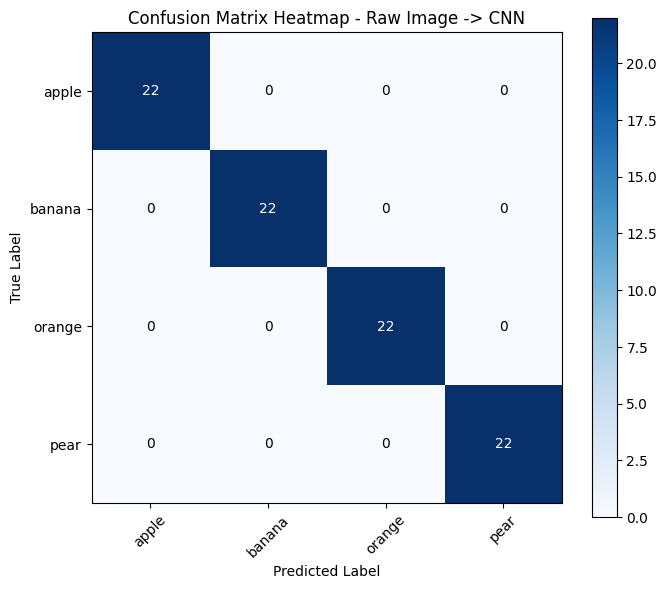

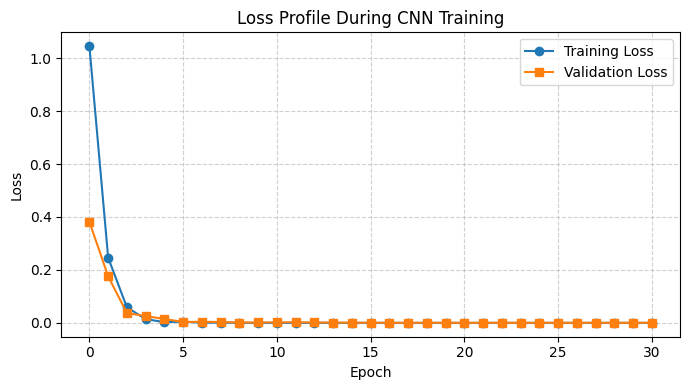

In [13]:
# Detailed evaluation for the Raw Image -> CNN classifier

from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support

# Generate predicted probabilities for all test images.
y_pred_prob_cnn = cnn.predict(Xte, verbose=0)

# Convert the probability vectors into final predicted class indices.
pred_cnn = np.argmax(y_pred_prob_cnn, axis=1)

# Save the test labels in a dedicated variable.
y_te_cnn = yte

# Build confusion matrix.
cm_cnn = confusion_matrix(y_te_cnn, pred_cnn)

# Compute summary metrics.
cnn_acc = accuracy_score(y_te_cnn, pred_cnn)
cnn_precision_macro, cnn_recall_macro, cnn_f1_macro, _ = precision_recall_fscore_support(
    y_te_cnn, pred_cnn, average="macro", zero_division=0
)
cnn_precision_weighted, cnn_recall_weighted, cnn_f1_weighted, _ = precision_recall_fscore_support(
    y_te_cnn, pred_cnn, average="weighted", zero_division=0
)

# Print the metrics clearly.
print("=== Raw Image -> CNN : Summary Metrics ===")
print(f"Accuracy            : {cnn_acc:.4f}")
print(f"Precision (macro)   : {cnn_precision_macro:.4f}")
print(f"Recall (macro)      : {cnn_recall_macro:.4f}")
print(f"F1-score (macro)    : {cnn_f1_macro:.4f}")
print(f"Precision (weighted): {cnn_precision_weighted:.4f}")
print(f"Recall (weighted)   : {cnn_recall_weighted:.4f}")
print(f"F1-score (weighted) : {cnn_f1_weighted:.4f}")

# Plot confusion matrix heatmap.
plt.figure(figsize=(7, 6))
plt.imshow(cm_cnn, interpolation='nearest', cmap='Blues')
plt.title("Confusion Matrix Heatmap - Raw Image -> CNN")
plt.colorbar()

tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

thresh = cm_cnn.max() / 2.0 if cm_cnn.size > 0 else 0.0
for r in range(cm_cnn.shape[0]):
    for c in range(cm_cnn.shape[1]):
        plt.text(
            c, r, str(cm_cnn[r, c]),
            ha="center",
            va="center",
            color="white" if cm_cnn[r, c] > thresh else "black"
        )

plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()

# Plot CNN loss profile from the Keras History object.
plt.figure(figsize=(7, 4))
plt.plot(hist2.history["loss"], marker='o', label="Training Loss")

# Validation loss is plotted if it is available in the history dictionary.
if "val_loss" in hist2.history:
    plt.plot(hist2.history["val_loss"], marker='s', label="Validation Loss")

plt.title("Loss Profile During CNN Training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 6) Compare Results
Record the accuracies from each pipeline and discuss which cues (shape/color/raw) work best on this dataset.

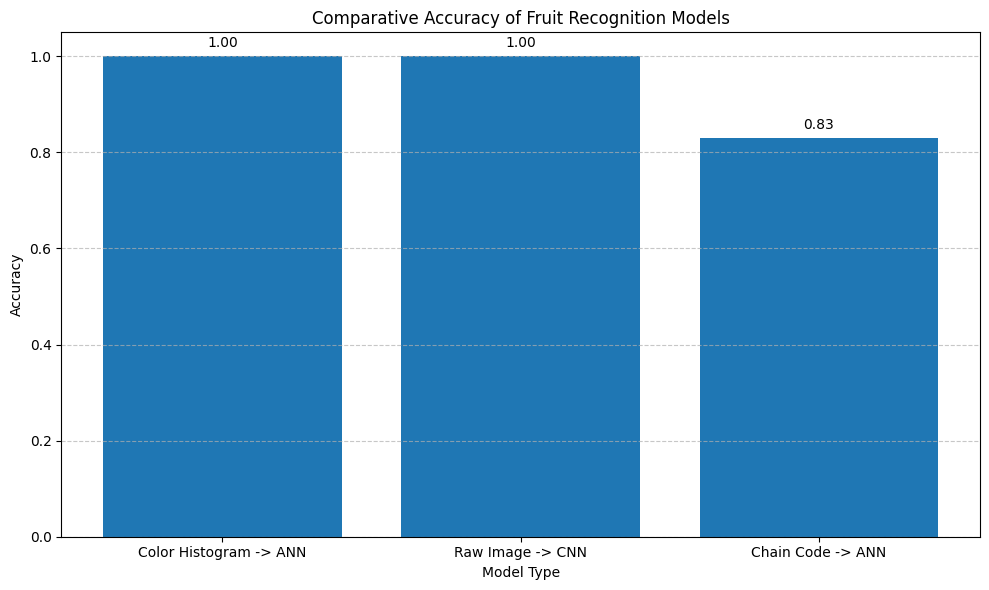

,Model,Accuracy
1,Color Histogram -> ANN,1.000000
2,Raw Image -> CNN,1.000000
0,Chain Code -> ANN,0.829545


In [14]:
# pandas is used to create a neat table for plotting
import pandas as pd

# matplotlib is used to draw the comparison bar chart
import matplotlib.pyplot as plt

# Collect the final accuracy values saved from the dedicated evaluation cells.
accuracies = {
    "Chain Code -> ANN": chain_acc,
    "Color Histogram -> ANN": hist_acc,
    "Raw Image -> CNN": cnn_acc
}

# Convert the dictionary into a DataFrame for easier sorting and plotting.
accuracy_df = pd.DataFrame(list(accuracies.items()), columns=['Model', 'Accuracy'])

# Sort models from best to lowest accuracy.
accuracy_df = accuracy_df.sort_values(by='Accuracy', ascending=False)

# Create the bar chart.
plt.figure(figsize=(10, 6))
plt.bar(accuracy_df['Model'], accuracy_df['Accuracy'])

# Label the axes and title.
plt.xlabel('Model Type')
plt.ylabel('Accuracy')
plt.title('Comparative Accuracy of Fruit Recognition Models')

# Accuracy values lie between 0 and 1, so keep the y-axis in that range.
plt.ylim(0, 1.05)

# Write the exact accuracy value above each bar.
for _, row in accuracy_df.iterrows():
    plt.text(row['Model'], row['Accuracy'] + 0.02, f"{row['Accuracy']:.2f}", ha='center')

# Add a light horizontal grid for easier reading.
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout and display the chart.
plt.tight_layout()
plt.show()

# Also display the values as a neat table.
accuracy_df
